# Практика 6

## 1. Преобразование Хаара: три уровня сжатия

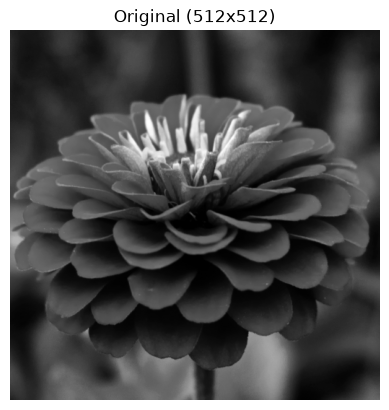

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt


def showpic(image, title, cmap='gray'):
    plt.figure()
    plt.imshow(image, cmap=cmap)
    plt.title(title)
    plt.axis('off')
    plt.show()


def haar_transform(image):
    rows, cols = image.shape
    result = np.zeros_like(image, dtype=np.float64)

    average = (image[:, 0::2] + image[:, 1::2]) / np.sqrt(2)
    difference = (image[:, 0::2] - image[:, 1::2]) / np.sqrt(2)

    result[:rows // 2, :cols // 2] = (average[0::2] + average[1::2]) / np.sqrt(2)
    result[rows // 2:, :cols // 2] = (average[0::2] - average[1::2]) / np.sqrt(2)
    result[:rows // 2, cols // 2:] = (difference[0::2] + difference[1::2]) / np.sqrt(2)
    result[rows // 2:, cols // 2:] = (difference[0::2] - difference[1::2]) / np.sqrt(2)

    return result


def inverse_haar(coefficients):
    rows, cols = coefficients.shape
    average = np.zeros((rows, cols // 2), dtype=np.float64)
    difference = np.zeros_like(average)

    ll = coefficients[:rows // 2, :cols // 2]
    lh = coefficients[rows // 2:, :cols // 2]
    hl = coefficients[:rows // 2, cols // 2:]
    hh = coefficients[rows // 2:, cols // 2:]

    average[0::2] = (ll + lh) / np.sqrt(2)
    average[1::2] = (ll - lh) / np.sqrt(2)
    difference[0::2] = (hl + hh) / np.sqrt(2)
    difference[1::2] = (hl - hh) / np.sqrt(2)

    result = np.zeros((rows, cols), dtype=np.float64)
    result[:, 0::2] = (average + difference) / np.sqrt(2)
    result[:, 1::2] = (average - difference) / np.sqrt(2)
    return result


image = cv2.imread('source/Flower.png', cv2.IMREAD_GRAYSCALE)
showpic(image, 'Original (512x512)')

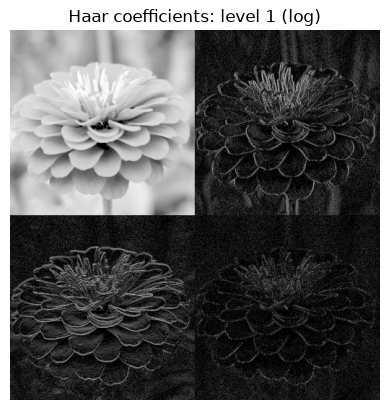

Level 1: approximation 256x256, MSE = 13.44


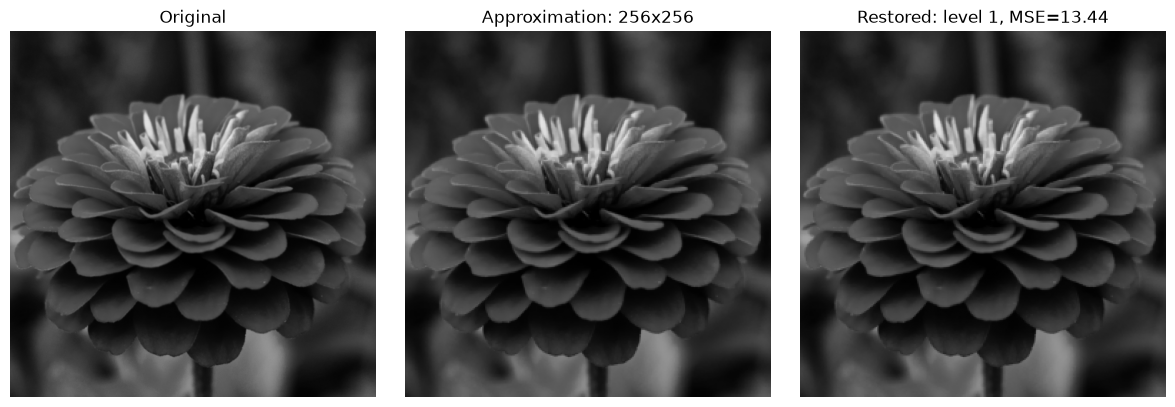

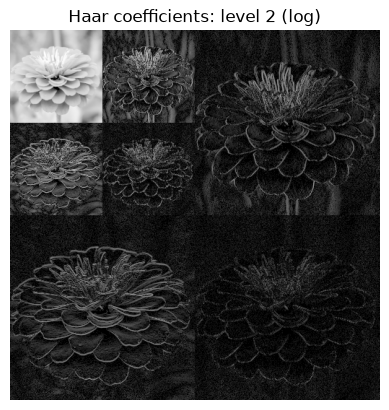

Level 2: approximation 128x128, MSE = 50.49


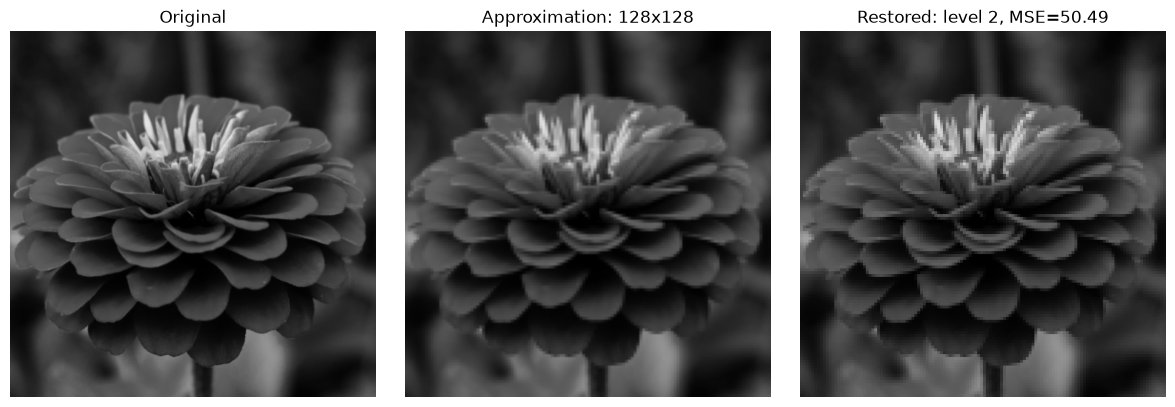

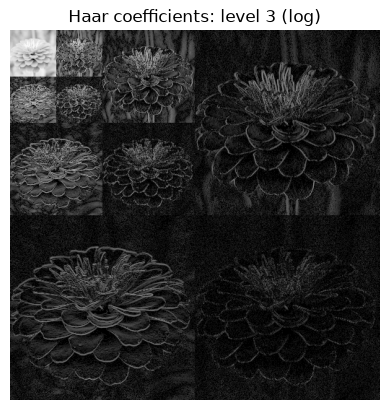

Level 3: approximation 64x64, MSE = 130.62


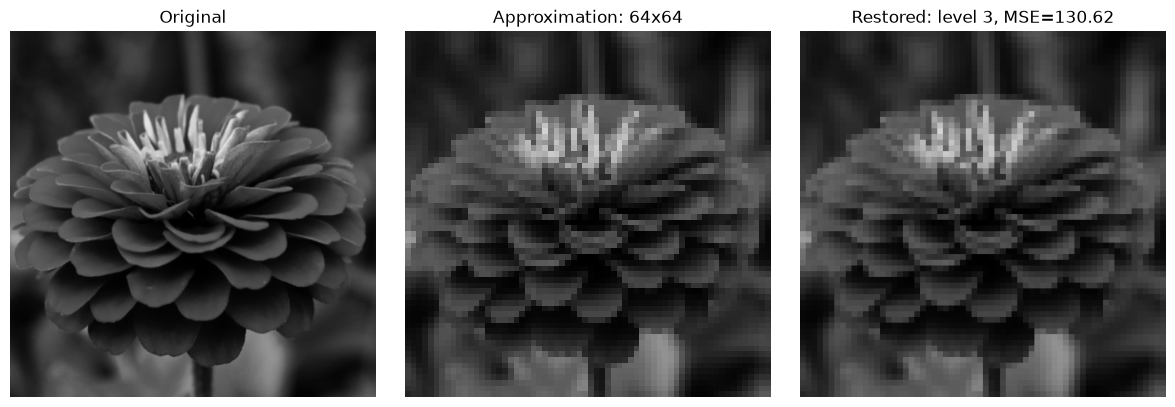

In [2]:
coefficients = image.astype(np.float64)
rows, cols = image.shape

for level in range(1, 4):
    h = rows // (2 ** (level - 1))
    w = cols // (2 ** (level - 1))
    coefficients[:h, :w] = haar_transform(coefficients[:h, :w])

    showpic(np.log1p(np.abs(coefficients)), f'Haar coefficients: level {level} (log)')

    # Keep only the approximation coefficients for compression.
    compressed = np.zeros_like(coefficients)
    compressed[:h // 2, :w // 2] = coefficients[:h // 2, :w // 2]

    for step in range(level, 0, -1):
        rh = rows // (2 ** (step - 1))
        rw = cols // (2 ** (step - 1))
        compressed[:rh, :rw] = inverse_haar(compressed[:rh, :rw])

    restored = np.clip(np.rint(compressed), 0, 255).astype(np.uint8)
    mse = np.mean((image.astype(np.float64) - restored) ** 2)
    print(f'Level {level}: approximation {h // 2}x{w // 2}, MSE = {mse:.2f}')

    plt.figure(figsize=(12, 4))
    plt.subplot(1, 3, 1)
    plt.imshow(image, cmap='gray', vmin=0, vmax=255)
    plt.title('Original')
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(coefficients[:h // 2, :w // 2] / (2 ** level), cmap='gray', vmin=0, vmax=255)
    plt.title(f'Approximation: {h // 2}x{w // 2}')
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(restored, cmap='gray', vmin=0, vmax=255)
    plt.title(f'Restored: level {level}, MSE={mse:.2f}')
    plt.axis('off')
    plt.tight_layout()
    plt.show()

## 2. Проверка обратного преобразования

In [3]:
reconstructed = coefficients.copy()
for step in range(3, 0, -1):
    h = rows // (2 ** (step - 1))
    w = cols // (2 ** (step - 1))
    reconstructed[:h, :w] = inverse_haar(reconstructed[:h, :w])

error = np.max(np.abs(image.astype(np.float64) - reconstructed))
print(f'Max reconstruction error (all coefficients): {error:.10f}')

Max reconstruction error (all coefficients): 0.0000000000
